# Build a synchrotron light-source lattice with Xsuite

**Intermediate tutorial · optics matching and radiation equilibrium · about 60–90 minutes with exercises**

We construct an ideal **3 GeV electron storage ring from scratch**, using 16 identical
**double-bend achromat (DBA) cells**. Each cell has two dipoles and a dispersion-free
straight shared with its neighbour, where an insertion device could be installed.
There are no external lattice files and no MAD-X dependency.

The design sequence is: define magnet families → match a periodic achromat → assemble
and survey the ring → correct chromaticity → add RF focusing → compute radiation
integrals → find the damped 6D equilibrium and beam sizes.

This is a compact teaching lattice, not the model of an operating facility. Its emittance
is about 52 nm, leaving substantial scope for optimization. Insertion devices,
magnet errors, coupling, collective effects and physical apertures are not included.
A successful linear match does not establish nonlinear acceptance or beam lifetime.

**Prerequisites:** Twiss parameters, dispersion, tunes, chromaticity and basic Python.
Run the notebook from top to bottom. When changing the cell geometry or its design
parameters, restart and run all cells to rebuild the derived lines.

## 1. Setup and conventions

Use a Python environment with `xsuite`, `numpy`, `scipy`, `pandas`, `matplotlib`,
`jupyterlab` and `ipykernel`. This notebook was validated with Xtrack 0.111.6 and
Xobjects 0.6.10; the first cell prints the versions in your kernel.
If needed, install packages in a separate cell with
`%pip install xsuite numpy scipy pandas matplotlib jupyterlab ipykernel`, then restart the kernel.
The first Xsuite calculation may take longer if tracking kernels need compilation.

Lengths are in metres, angles in radians, particle energies in eV, quadrupole `k1`
in m⁻² and sextupole `k2` in m⁻³. Emittances below are **geometric**, not normalized.
We first use `twiss4d()` with radiation off, so RF focusing is excluded from the optics match.

In [1]:
%matplotlib inline
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c, hbar, m_e
from IPython.display import display
import xtrack as xt

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'font.size': 11})
for package in ['xtrack', 'xobjects', 'numpy', 'scipy']:
    print(f'{package}: {metadata.version(package)}')

xtrack: 0.111.6
xobjects: 0.6.10
numpy: 2.4.6
scipy: 1.17.0


## 2. Define magnet families and a symmetric cell

We choose 16 cells and two equal sector bends per cell, so each bend turns the
reference trajectory through $\theta_b = 2\pi/(2N_c)$. Xsuite's `Bend` uses the
reference curvature to set its dipole field by default. The dipoles have no
quadrupole gradient or additional pole-face angles.

The cell has **one focusing quadrupole between the bends**, with an outer doublet
on each side. This gives three quadrupole families: Q1, Q2 and QC. Their initial
strengths are chosen near a stable solution. Two sextupole families are initially off.

The half-cell runs from the centre of a straight to the entrance of QC:

`straight centre — 2 m drift — Q1 — Q2 — B — SD — SF`

The full cell is `half_cell + QC + mirrored_half_cell`. QC is one physical
0.25 m quadrupole; it is not duplicated in the half-cells. In total there are five
quadrupoles per cell: two Q1, two Q2 and one QC.

Neighbouring cells join their 2 m end drifts into a **4 m magnet-free straight**.
The `-half_cell` syntax reverses element order to make a mirror; it does not reverse
magnet polarities. SD sits nearer each bend and SF nearer the central focusing quadrupole.

In [2]:
energy_eV = 3e9
n_cells = 16
qx_target, qy_target = 11.22, 4.18

env = xt.Environment()
env.set_particle_ref('electron', energy0=energy_eV)
env.vars({
    'l_bend': 1.5,
    'theta_bend': 2 * np.pi / (2 * n_cells),
    'kq1': 2.9,
    'kq2': -3.0,
    'kqc': 3.3,
    'ksf': 0.0,
    'ksd': 0.0,
})

# Three quadrupole families; one central QC per cell.
for name, length in [('dss', 2.0), ('d03', 0.3), ('d05', 0.5),
                     ('d075', 0.75), ('d025', 0.25)]:
    env.new(name, xt.Drift, length=length)
for name in ['q1', 'q2', 'qc']:
    env.new(name, xt.Quadrupole, length=0.25, k1='k' + name)
env.new('bend', xt.Bend, length='l_bend', angle='theta_bend')
env.new('sf', xt.Sextupole, length=0.15, k2='ksf')
env.new('sd', xt.Sextupole, length=0.15, k2='ksd')

half_cell = env.new_line(components=[
    'dss', 'q1', 'd03', 'q2', 'd05', 'bend',
    'd03', 'sd', 'd075', 'sf', 'd025',
])
cell = env.new_line(components=[
    env.new('ss', xt.Marker),
    half_cell, 'qc', -half_cell,
    env.new('cell_end', xt.Marker),
])
assert list(cell.element_names).count('qc') == 1
assert np.count_nonzero(cell.get_table().element_type == 'Quadrupole') == 5
print(f'Cell length: {cell.get_length():.3f} m')
print(f'Bend angle: {np.degrees(env["theta_bend"]):.3f} degrees')
cell.get_table().show(cols=['s', 'element_type'])

Cell length: 13.050 m
Bend angle: 11.250 degrees
name                   s element_type
ss                     0 Marker      
dss::0                 0 Drift       
q1::0                  2 Quadrupole  
d03::0              2.25 Drift       
q2::0               2.55 Quadrupole  
d05::0               2.8 Drift       
bend::0              3.3 Bend        
d03::1               4.8 Drift       
sd::0                5.1 Sextupole   
d075::0             5.25 Drift       
sf::0                  6 Sextupole   
d025::0             6.15 Drift       
qc                   6.4 Quadrupole  
d025::1             6.65 Drift       
sf::1                6.9 Sextupole   
d075::1             7.05 Drift       
sd::1                7.8 Sextupole   
d03::2              7.95 Drift       
bend::1             8.25 Bend        
d05::1              9.75 Drift       
q2::1              10.25 Quadrupole  
d03::3              10.5 Drift       
q1::1               10.8 Quadrupole  
dss::1             11.05 Drift       
c

In [3]:
tw_seed = cell.twiss4d()
print(f'Seed cell phase advances / 2π: {tw_seed.qx:.5f}, {tw_seed.qy:.5f}')
print(f'Seed dispersion at straight centre: {tw_seed["dx", "ss"]:.5f} m')

Seed cell phase advances / 2π: 0.70423, 0.24313
Seed dispersion at straight centre: 0.01917 m


## 3. Match the periodic achromat

For identical cells the ring tunes are $Q_x=N_c\mu_x/(2\pi)$ and
$Q_y=N_c\mu_y/(2\pi)$. The cell targets below are the phase advances **in turns**,
not the fractional parts of the ring tunes.

We vary three quadrupole strengths to impose three conditions:

| Target | Purpose |
|---|---|
| Cell `qx = 11.22 / 16` | Choose horizontal ring tune |
| Cell `qy = 4.18 / 16` | Choose vertical ring tune |
| `dx = 0` at `ss` | Make the straight achromatic |

The central focusing quadrupole makes the two-bend section achromatic; the outer
doublets provide control of the periodic focusing. Mirror symmetry makes
$\alpha_x$, $\alpha_y$ and $D'_x$ vanish at the straight centre. We verify these
conditions after matching, rather than adding redundant targets.

**The straight-section beta functions are now results of the match**, not extra
constraints. Fixing both tunes, dispersion and a beta function would require an
additional independent knob. For the default solution, $\beta_x$ at the straight
centre is about 14.2 m.

The chosen tunes correspond to cell phase advances of 252.45° and 94.05°. These
are stable teaching targets, not a working point optimized for emittance or nonlinear
acceptance. A phase-advance scan is a useful next design study.

`solve=False` lets us inspect the residuals before running the optimizer. More
examples are in the [Xsuite matching guide](https://xsuite.readthedocs.io/en/latest/match.html).

In [4]:
optics_match = cell.match(
    solve=False,
    method='4d',
    vary=xt.VaryList(['kq1', 'kq2', 'kqc'], step=1e-5, limits=[-8, 8]),
    targets=[
        xt.TargetSet(qx=qx_target / n_cells, qy=qy_target / n_cells, tol=1e-8),
        xt.TargetSet(dx=0, at='ss', tol=1e-8),
    ],
)
optics_match.target_status()
optics_match.solve()
optics_match.target_status()
optics_match.vary_status()

Target status:               
id state tag   tol_met       residue   current_val    target_val description                                 
0  ON    qx      False    0.00298108      0.704231       0.70125 'qx', val=0.70125, tol=1e-08, weight=10     
1  ON    qy      False    -0.0181201       0.24313       0.26125 'qy', val=0.26125, tol=1e-08, weight=10     
2  ON    ss_dx   False     0.0191707     0.0191707             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...
                                             


Optimize - start penalty: 0.2655                         



Optimize - end penalty:  1.03329e-10                            


Target status:               
id state tag   tol_met       residue   current_val    target_val description                                 
0  ON    qx       True   -7.9684e-12       0.70125       0.70125 'qx', val=0.70125, tol=1e-08, weight=10     
1  ON    qy       True  -6.27942e-13       0.26125       0.26125 'qy', val=0.26125, tol=1e-08, weight=10     
2  ON    ss_dx    True  -6.54819e-12  -6.54819e-12             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kq1           -8       2.90044           8           2.9         1e-05             1
1  ON        OK  kq2           -8      -3.02407           8            -3         1e-05             1
2  ON        OK  kqc           -8       3.34136           8           3.3         1e-05             1


Periodic achromat and symmetry checks passed.
Straight-centre βx = 14.218 m
Straight-centre βy = 10.571 m


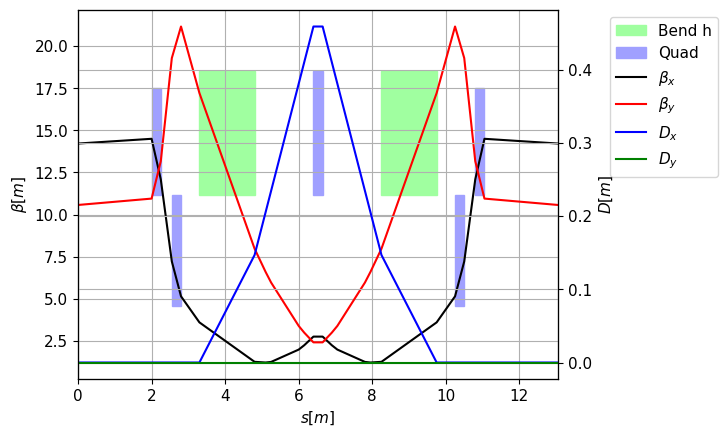

In [5]:
tw_cell = cell.twiss4d()
np.testing.assert_allclose([tw_cell.qx, tw_cell.qy],
                           np.array([qx_target, qy_target]) / n_cells, atol=1e-8, rtol=0)
np.testing.assert_allclose([tw_cell['dx', 'ss'], tw_cell['dpx', 'ss'],
                           tw_cell['alfx', 'ss'], tw_cell['alfy', 'ss']],
                          0, atol=1e-6)
print('Periodic achromat and symmetry checks passed.')
print(f'Straight-centre βx = {tw_cell["betx", "ss"]:.3f} m')
print(f'Straight-centre βy = {tw_cell["bety", "ss"]:.3f} m')
tw_cell.plot()
plt.show()

**Read the plot:** dispersion is zero in the straight and rises inside the achromat.
The sextupoles lie in dispersive regions, at different ratios of $\beta_x/\beta_y$.
An off-momentum particle has $x\simeq D_x\delta$ there, so a sextupole supplies an
effective quadrupole term proportional to $k_2D_x\delta$. This is the mechanism for
chromaticity correction. The nonlinear kicks remain even after the linear
chromaticities have been corrected.

## 4. Assemble and survey the full ring

The RF cavity is a zero-length element at the centre of one straight. Its voltage
and frequency remain zero until we reach longitudinal dynamics.
`replace_all_repeated_elements()` gives each physical occurrence its own element,
while preserving the expressions that connect magnets to common family strengths.
This is useful before slicing or applying location-dependent changes.

In [6]:
ring = env.new_line(components=[
    env.new('rf', xt.Cavity, voltage=0, frequency=0, phase=np.pi),
    n_cells * cell,
])
ring.replace_all_repeated_elements()
circumference = ring.get_length()
survey = ring.survey()
closure_error = np.linalg.norm([
    survey.X[-1] - survey.X[0],
    survey.Y[-1] - survey.Y[0],
    survey.Z[-1] - survey.Z[0],
])
assert closure_error < 1e-8
np.testing.assert_allclose(2 * n_cells * env['theta_bend'], 2 * np.pi)

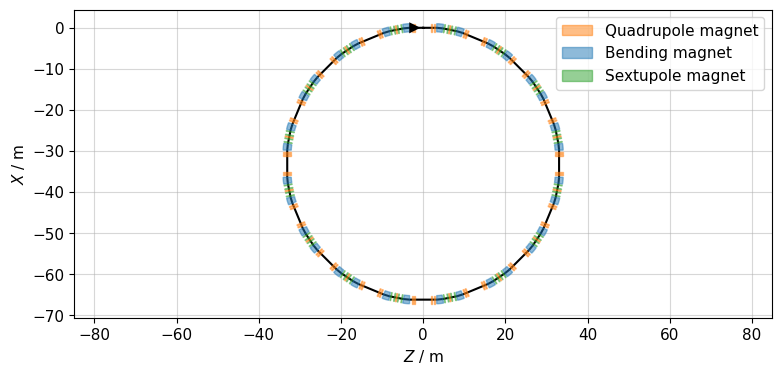

In [7]:
survey.plot()

In [8]:
tw_natural = ring.twiss4d()
np.testing.assert_allclose([tw_natural.qx, tw_natural.qy],
                          [qx_target, qy_target], atol=1e-6, rtol=0)
display(pd.Series({
    'Circumference [m]': circumference,
    'Qx': tw_natural.qx,
    'Qy': tw_natural.qy,
    'Natural chromaticity x': tw_natural.dqx,
    'Natural chromaticity y': tw_natural.dqy,
    'Momentum compaction': tw_natural.momentum_compaction_factor,
}, name='Bare ring'))

Circumference [m]         208.800000
Qx                         11.220000
Qy                          4.180000
Natural chromaticity x    -17.005206
Natural chromaticity y    -16.113145
Momentum compaction         0.001474
Name: Bare ring, dtype: float64

## 5. Correct chromaticity with two sextupole families

Chromaticity is $\xi=dQ/d\delta$, where $\delta=(p-p_0)/p_0$.
We target $\xi_x=\xi_y=+1$ for the full ring. At the ideal on-momentum closed orbit,
sextupoles do not change the linear focusing, so the quadrupole match is preserved.

In [9]:
chromaticity_match = ring.match(
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3, limits=[-200, 200]),
    targets=xt.TargetSet(dqx=1.0, dqy=1.0, tol=1e-5),
)
chromaticity_match.target_status()
chromaticity_match.vary_status()
tw_corrected = ring.twiss4d()
np.testing.assert_allclose([tw_corrected.dqx, tw_corrected.dqy], [1, 1], atol=1e-5, rtol=0)
np.testing.assert_allclose([tw_corrected.qx, tw_corrected.qy],
                          [qx_target, qy_target], atol=1e-6, rtol=0)

display(pd.DataFrame({
    'Natural': [tw_natural.dqx, tw_natural.dqy],
    'Corrected': [tw_corrected.dqx, tw_corrected.dqy],
}, index=['ξx', 'ξy']))

Optimize - start penalty: 24.84                         


Matching: model call n. 10 penalty = 3.0368e-02              

Matching: model call n. 16 penalty = 7.7240e-07              


Optimize - end penalty:  7.72398e-07                            


Target status:               
id state tag tol_met       residue   current_val    target_val description                      
0  ON    dqx    True  -7.72398e-07      0.999999             1 'dqx', val=1, tol=1e-05, weight=1
1  ON    dqy    True   -1.9984e-11             1             1 'dqy', val=1, tol=1e-05, weight=1
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  ksf         -200       95.1986         200             0         0.001             1
1  ON        OK  ksd         -200      -119.362         200             0         0.001             1


,Natural,Corrected
ξx,-17.005206,0.999999
ξy,-16.113145,1.000000


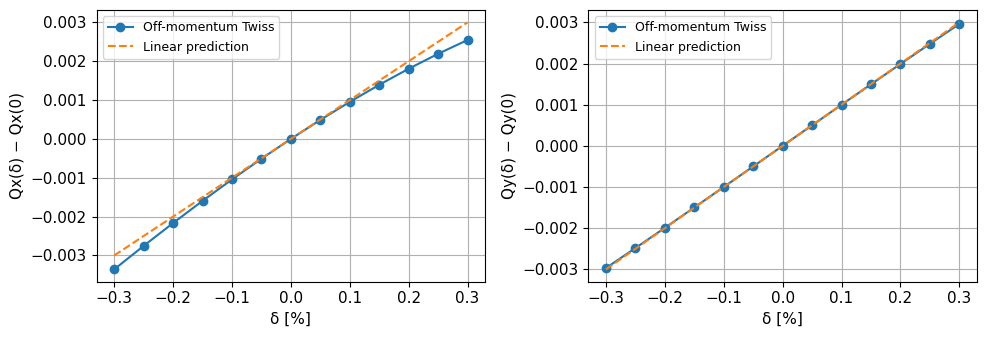

In [10]:
# Small momentum offsets probe local chromatic behaviour, not momentum acceptance.
deltas = np.linspace(-0.003, 0.003, 13)
tune_scan = np.array([[tw.qx, tw.qy] for tw in
                      (ring.twiss4d(delta0=delta) for delta in deltas)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, (ax, tune, chrom, plane) in enumerate(zip(
        axes, [tw_corrected.qx, tw_corrected.qy],
        [tw_corrected.dqx, tw_corrected.dqy], ['x', 'y'])):
    ax.plot(100 * deltas, tune_scan[:, j] - tune, 'o-', label='Off-momentum Twiss')
    ax.plot(100 * deltas, chrom * deltas, '--', label='Linear prediction')
    ax.set(xlabel='δ [%]', ylabel=f'Q{plane}(δ) − Q{plane}(0)')
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Add RF focusing

Choose an integer harmonic number $h$ that places $f_\mathrm{RF}=h\beta_0c/C$
near 500 MHz. The cavity voltage is 3 MV.

With positive momentum compaction, the no-radiation stable phase in the Xsuite
cavity convention used here is `phase = π` (radians). The cavity energy kick uses
the magnitude of the reference charge. Radiation will shift the synchronous
particle away from this zero-energy-gain phase so that the RF restores its loss.

In [11]:
beta0 = float(ring.particle_ref.beta0[0])
f_rev = beta0 * c / circumference
harmonic_number = int(round(500e6 / f_rev))
ring['rf'].frequency = harmonic_number * f_rev
ring['rf'].voltage = 3e6
ring['rf'].phase = np.pi

tw_6d_no_rad = ring.twiss(method='6d')
assert tw_6d_no_rad.qs > 0
print(f'Revolution frequency: {f_rev / 1e6:.4f} MHz')
print(f'Harmonic number: {harmonic_number}')
print(f'RF frequency: {ring["rf"].frequency / 1e6:.4f} MHz')
print(f'No-radiation synchrotron tune: {tw_6d_no_rad.qs:.5f}')

Revolution frequency: 1.4358 MHz
Harmonic number: 348
RF frequency: 499.6541 MHz
No-radiation synchrotron tune: 0.00904


## 7. Resolve the magnets and check convergence

Radiation integrals depend on the optics **inside** the bends. A table containing
only magnet entrances may be too coarse. We make independent copies of the
matched ring, subdivide the bends into 4, 8, 16 and 32 thick slices, and compare the
computed emittance. Quadrupoles and sextupoles get two thick slices each.

The copies retain the magnet-family expressions but have independent environments.
The design ring remains available for further matching. The final, finest copy is
used for the radiation calculations below. This short scan checks discretization;
it does not measure the accuracy of the idealized physical model.

Subdividing a thick sextupole also changes its numerical integration. We therefore
rematch the two chromaticities on the final sliced copy, so the radiation model
also has the requested chromaticities. This leaves the ideal on-momentum linear
optics and radiation integrals unchanged within numerical precision.

In [12]:
convergence_rows = []
for n_slices in [4, 8, 16, 32]:
    candidate = ring.copy()
    candidate.slice_thick_elements(slicing_strategies=[
        xt.Strategy(slicing=None),
        xt.Strategy(slicing=xt.Uniform(n_slices, mode='thick'), element_type=xt.Bend),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Sextupole),
    ])
    tw_candidate = candidate.twiss4d(radiation_integrals=True)
    convergence_rows.append({
        'Slices / bend': n_slices,
        'εx [nm]': 1e9 * tw_candidate.rad_int_eq_gemitt_x,
        'σδ [10⁻³]': 1e3 * tw_candidate.rad_int_sigma_delta,
        'U0 [keV]': 1e-3 * tw_candidate.rad_int_energy_loss,
    })
    radiation_ring, tw_integrals = candidate, tw_candidate

convergence = pd.DataFrame(convergence_rows).set_index('Slices / bend')
display(convergence)
last_change = abs(convergence['εx [nm]'].iloc[-1] / convergence['εx [nm]'].iloc[-2] - 1)
print(f'Change in εx from 16 to 32 slices: {100 * last_change:.4f}%')
assert last_change < 0.002
np.testing.assert_allclose([tw_integrals.qx, tw_integrals.qy],
                          [qx_target, qy_target], atol=1e-5, rtol=0)

# Restore the chromaticity targets after changing the integration of thick sextupoles.
radiation_ring.match(
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3, limits=[-200, 200]),
    targets=xt.TargetSet(dqx=1.0, dqy=1.0, tol=1e-5),
)
tw_integrals = radiation_ring.twiss4d(radiation_integrals=True)
np.testing.assert_allclose([tw_integrals.dqx, tw_integrals.dqy],
                          [1, 1], atol=1e-5, rtol=0)

Slicing line:   0%|          | 0/401 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/401 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/401 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/401 [00:00<?, ?it/s]

,εx [nm],σδ [10⁻³],U0 [keV]
Slices / bend,,,
4,53.009569,0.928214,937.959368
8,52.275151,0.928248,937.959367
16,52.090919,0.928257,937.959368
32,52.044822,0.928259,937.959368


Change in εx from 16 to 32 slices: 0.0885%


Optimize - start penalty: 0.03694                         



Optimize - end penalty:  3.7309e-07                            


## 8. Connect radiation integrals to equilibrium

For this planar, uncoupled ring, write

$$I_2=\oint\frac{ds}{\rho^2},\qquad
I_3=\oint\frac{ds}{|\rho|^3},\qquad
I_5=\oint\frac{\mathcal H_x}{|\rho|^3}\,ds,$$

$$\mathcal H_x=\gamma_xD_x^2+2\alpha_xD_xD'_x+\beta_xD_x'^2,
\qquad \gamma_x=\frac{1+\alpha_x^2}{\beta_x}.$$

For the sector-bend model used here,
$I_{4x}=\oint D_x\rho^{-1}(\rho^{-2}+2k_1)\,ds$; there are no additional
pole-face terms. With no vertical dispersion, the partition numbers are
$J_x=1-I_{4x}/I_2$, $J_y=1$, and $J_\epsilon=2+I_{4x}/I_2$.
The equilibrium predictions are

$$\epsilon_x=C_q\gamma_0^2\frac{I_5}{J_xI_2},\qquad
\sigma_\delta^2=C_q\gamma_0^2\frac{I_3}{J_\epsilon I_2},\qquad
U_0=\frac{C_\gamma}{2\pi}E_0^4I_2.$$

Here $C_q\simeq3.832\times10^{-13}$ m; with $E_0$ in GeV and
$C_\gamma\simeq8.846\times10^{-5}$ m/GeV³, $U_0$ is in GeV.
The amplitude damping times are $\tau_i=2E_0T_0/(J_iU_0)$.

Reducing $\mathcal H_x$ **where the beam bends** reduces quantum excitation.
Zero dispersion at a source point is useful, but alone does not imply a small
natural emittance. The Lorentz factor $\gamma_0$ and Twiss $\gamma_x$ are different quantities.

In [13]:
I2 = tw_integrals.rad_int_i2
I3 = tw_integrals.rad_int_i3
I4 = tw_integrals.rad_int_i4x
I5 = tw_integrals.rad_int_i5x
J = np.array([1 - I4 / I2, 1.0, 2 + I4 / I2])
gamma0 = float(ring.particle_ref.gamma0[0])
Cq = 55 / (32 * np.sqrt(3)) * hbar / (m_e * c)
Cgamma = 8.846056192e-5  # m / GeV^3

emit_formula = Cq * gamma0**2 * I5 / (J[0] * I2)
sigma_delta_formula = np.sqrt(Cq * gamma0**2 * I3 / (J[2] * I2))
loss_formula_eV = Cgamma / (2 * np.pi) * (energy_eV / 1e9)**4 * I2 * 1e9
tau_integrals = 2 * energy_eV / (J * tw_integrals.rad_int_energy_loss) / f_rev

# Independent geometry checks for equal, pure sector bends.
rho = env['l_bend'] / env['theta_bend']
np.testing.assert_allclose(I2, 2 * np.pi / rho, rtol=1e-5)
np.testing.assert_allclose(I3, 2 * np.pi / rho**2, rtol=1e-5)
np.testing.assert_allclose(emit_formula, tw_integrals.rad_int_eq_gemitt_x, rtol=1e-5)
np.testing.assert_allclose(sigma_delta_formula, tw_integrals.rad_int_sigma_delta, rtol=1e-5)
np.testing.assert_allclose(loss_formula_eV, tw_integrals.rad_int_energy_loss, rtol=1e-4)
assert np.all(J > 0)

display(pd.Series({
    'Bending radius [m]': rho,
    'I2 [1/m]': I2,
    'I3 [1/m²]': I3,
    'I4x [1/m]': I4,
    'I5x [1/m]': I5,
    'εx [nm]': 1e9 * emit_formula,
    'σδ': sigma_delta_formula,
    'U0 [keV]': loss_formula_eV / 1e3,
}, name='Radiation-integral prediction'))
display(pd.DataFrame({'Partition number': J, 'Amplitude damping time [ms]': 1e3 * tau_integrals},
                     index=['x', 'y', 'longitudinal']))

Bending radius [m]      7.639437
I2 [1/m]                0.822467
I3 [1/m²]               0.107661
I4x [1/m]               0.005277
I5x [1/m]               0.003220
εx [nm]                52.044822
σδ                      0.000928
U0 [keV]              937.936299
Name: Radiation-integral prediction, dtype: float64

,Partition number,Amplitude damping time [ms]
x,0.993584,4.484072
y,1.000000,4.455301
longitudinal,2.006416,2.220527


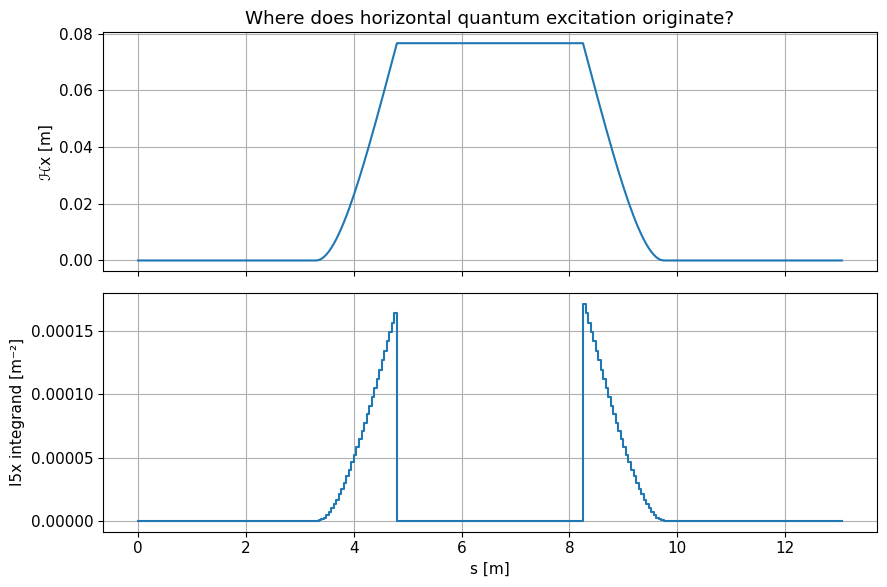

In [14]:
# Examine the radiation integrand over the first cell.
first_cell = tw_integrals.s <= cell.get_length() + 1e-9
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6))
axes[0].plot(tw_integrals.s[first_cell], tw_integrals.rad_int_curly_hx[first_cell])
axes[0].set(ylabel='ℋx [m]', title='Where does horizontal quantum excitation originate?')
axes[1].plot(tw_integrals.s[first_cell],
             tw_integrals.rad_int_i5x_integrand[first_cell], drawstyle='steps-post')
axes[1].set(xlabel='s [m]', ylabel='I5x integrand [m⁻²]')
fig.tight_layout()
plt.show()

## 9. Solve the 6D equilibrium with radiation

Enable the mean energy loss and compute a damped periodic solution.
`radiation_analysis=True` adds damping rates and equilibrium emittances from the
linear radiation analysis. Although mean-mode **tracking** has no random photon
kicks, this **analysis** includes quantum diffusion when calculating equilibrium.
See [Xsuite's radiation guide](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html).

The RF voltage must exceed the energy loss per turn (in eV for a singly charged
particle). The 6D closed-orbit solver finds the synchronous longitudinal offset.
We do not taper the magnets here: their strengths stay at the nominal design
values, so the energy sawtooth can slightly alter the orbit and optics.

In [15]:
assert radiation_ring['rf'].voltage > tw_integrals.rad_int_energy_loss
radiation_ring.configure_radiation(model='mean')
tw_rad = radiation_ring.twiss(method='6d', radiation_analysis=True)
assert tw_rad.qs > 0
assert np.all(tw_rad.damping_constants_s > 0)
assert tw_rad.eq_gemitt_x > 0
assert tw_rad.eq_gemitt_zeta > 0

comparison = pd.DataFrame({
    'Radiation integrals': [tw_integrals.rad_int_energy_loss / 1e3,
                           tw_integrals.rad_int_eq_gemitt_x * 1e9,
                           *list(1e3 * tau_integrals)],
    '6D radiation analysis': [tw_rad.energy_loss / 1e3, tw_rad.eq_gemitt_x * 1e9,
                             *list(1e3 / tw_rad.damping_constants_s)],
}, index=['U0 [keV]', 'εx [nm]', 'τx [ms]', 'τy [ms]', 'τε [ms]'])
comparison['Difference [%]'] = 100 * (
    comparison['6D radiation analysis'] / comparison['Radiation integrals'] - 1)
display(comparison)
print('6D partition numbers:', tw_rad.partition_numbers)
print(f'Synchrotron tune with radiation: {tw_rad.qs:.5f}')
np.testing.assert_allclose(tw_rad.energy_loss, tw_integrals.rad_int_energy_loss, rtol=0.01)
np.testing.assert_allclose(tw_rad.eq_gemitt_x, tw_integrals.rad_int_eq_gemitt_x, rtol=0.01)

,Radiation integrals,6D radiation analysis,Difference [%]
U0 [keV],937.959368,937.959759,0.000042
εx [nm],52.044822,52.045327,0.000969
τx [ms],4.484072,4.484041,-0.000685
τy [ms],4.455301,4.455295,-0.000135
τε [ms],2.220527,2.220525,-0.000066


6D partition numbers: [0.9935903  1.00000111 2.00641713]
Synchrotron tune with radiation: 0.00881


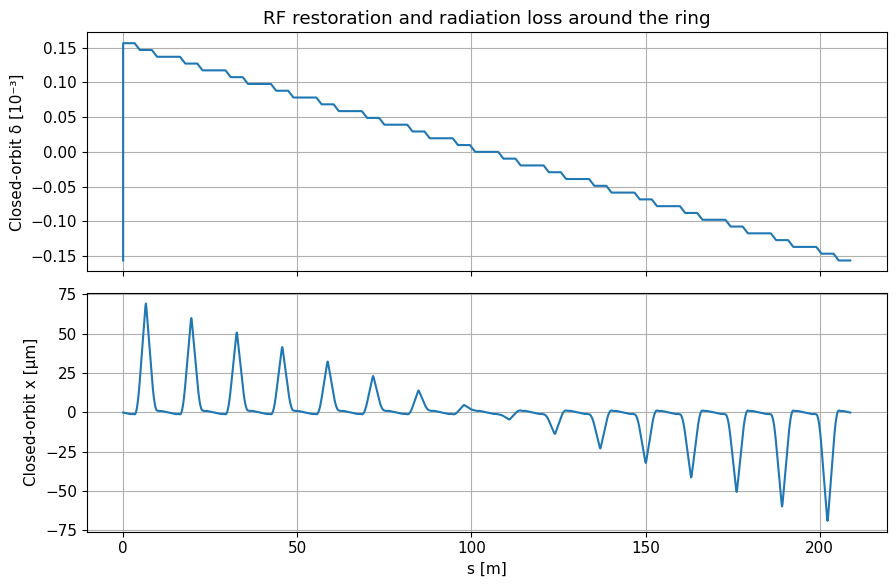

In [16]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6))
axes[0].plot(tw_rad.s, 1e3 * tw_rad.delta)
axes[0].set(ylabel='Closed-orbit δ [10⁻³]', title='RF restoration and radiation loss around the ring')
axes[1].plot(tw_rad.s, 1e6 * tw_rad.x)
axes[1].set(xlabel='s [m]', ylabel='Closed-orbit x [µm]')
fig.tight_layout()
plt.show()

## 10. Equilibrium beam sizes at a source point

In an uncoupled approximation, $\sigma_x^2\simeq\beta_x\epsilon_x+D_x^2\sigma_\delta^2$.
Use the full 6D covariance to include the dispersive contribution consistently.
At these energies $p_\zeta=\Delta E/(\beta_0p_0c)$ and $\delta$ agree to linear order,
so `sigma_pzeta` gives the small-amplitude momentum spread.

The first row is the RF / straight centre. The ideal planar model has essentially
zero vertical equilibrium emittance: it contains neither coupling nor vertical
dispersion, and the radiation model neglects the photon opening-angle contribution.
Do not interpret that as a prediction of a zero-height real beam.
For an illustrative vertical beam size we also evaluate **an assumed**
$\epsilon_y=0.01\epsilon_x$, leaving the horizontal emittance fixed.
This is a beam-size assumption, not a calculation of coupling or emittance sharing.

Natural εx [nm]                              5.204533e+01
Ideal-model εy [nm]                          3.222065e-41
σδ at source                                 9.283780e-04
Bunch length σz [mm]                         5.164503e+00
Horizontal source size σx [µm]               8.602370e+02
Assumed εy [nm]                              5.204533e-01
Vertical source size with assumed εy [µm]    7.417363e+01
Name: At the first straight centre, dtype: float64

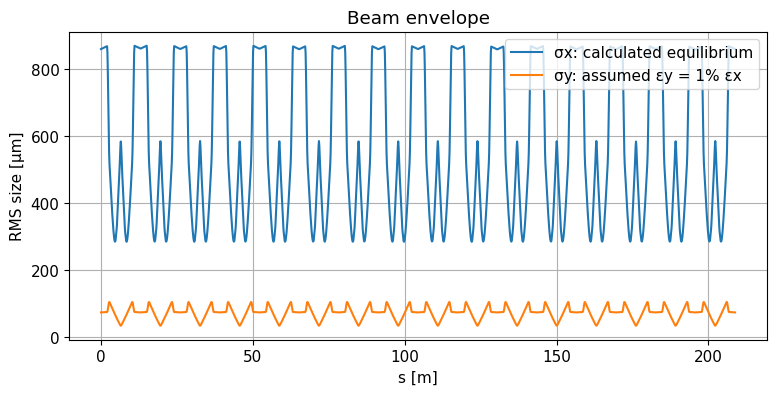

In [17]:
cov_equilibrium = tw_rad.get_beam_covariance(
    gemitt_x=tw_rad.eq_gemitt_x,
    gemitt_y=tw_rad.eq_gemitt_y,
    gemitt_zeta=tw_rad.eq_gemitt_zeta,
)
assumed_emit_y = 0.01 * tw_rad.eq_gemitt_x
cov_illustrative = tw_rad.get_beam_covariance(
    gemitt_x=tw_rad.eq_gemitt_x,
    gemitt_y=assumed_emit_y,
    gemitt_zeta=tw_rad.eq_gemitt_zeta,
)
display(pd.Series({
    'Natural εx [nm]': tw_rad.eq_gemitt_x * 1e9,
    'Ideal-model εy [nm]': tw_rad.eq_gemitt_y * 1e9,
    'σδ at source': cov_equilibrium.sigma_pzeta[0],
    'Bunch length σz [mm]': cov_equilibrium.sigma_zeta[0] * 1e3,
    'Horizontal source size σx [µm]': cov_equilibrium.sigma_x[0] * 1e6,
    'Assumed εy [nm]': assumed_emit_y * 1e9,
    'Vertical source size with assumed εy [µm]': cov_illustrative.sigma_y[0] * 1e6,
}, name='At the first straight centre'))
np.testing.assert_allclose(cov_equilibrium.sigma_pzeta[0],
                          tw_integrals.rad_int_sigma_delta, rtol=0.02)

fig, ax = plt.subplots()
ax.plot(tw_rad.s, 1e6 * cov_equilibrium.sigma_x, label='σx: calculated equilibrium')
ax.plot(tw_rad.s, 1e6 * cov_illustrative.sigma_y, label='σy: assumed εy = 1% εx')
ax.set(xlabel='s [m]', ylabel='RMS size [µm]', title='Beam envelope')
ax.legend()
plt.show()

## 11. Exercises and design studies

1. **Retune the ring.** Change the tune targets to $(11.28, 4.24)$ and rerun from
   the beginning. Inspect all matching residuals, natural chromaticities, sextupole
   strengths and equilibrium emittance. Why do the sextupoles need rematching?
2. **Scan the horizontal phase advance.** Try `qx_target = 10.6, 11.22, 11.8`,
   keeping `qy_target = 4.18` and rerunning from the beginning each time. Record
   emittance, the resulting straight-section beta functions, source size, maximum
   beta and sextupole strengths. Compare the $I_5$ integrands. Which optics gives
   the lowest emittance, and what other properties change?
3. **Change energy.** Try 2 and 4 GeV while keeping the geometry and normalized
   magnet strengths fixed. Check $U_0\propto E^4$, $\epsilon_x\propto E^2$ and
   $\sigma_\delta\propto E$. At 4 GeV the loss is about 2.96 MeV, barely below the 3 MV RF voltage:
   use 5 MV before the 6D radiation calculation to retain useful RF margin. Physically, keeping `k1` and `k2` fixed
   while changing energy requires changing the magnet fields.
4. **Raise the RF voltage.** Try 5 MV at 3 GeV. Compare synchrotron tune, bunch
   length, transverse emittance and energy spread. Which quantities are set mainly
   by the magnetic lattice?
5. **Extend the convergence study.** Add 64 slices per bend. Compare the radiation
   integrals and the 6D radiation result. Explain why the two methods need not agree
   to machine precision even when each has converged.
6. **Go beyond linear optics.** On a separate copy, track particles with increasing
   transverse amplitudes and momentum offsets. Measure survival over a stated turn
   count and inspect tune footprints. Do not identify the small Twiss momentum scan
   above with a dynamic-aperture or lifetime calculation.

For a tracking extension, `model='mean'` damps particles towards the closed orbit;
`model='quantum'` adds stochastic photon emission. Compute Twiss and prepare
initial conditions before switching to quantum mode. Demonstrating equilibrium
with tracking requires many particles and several damping times, not a few turns.

## 12. Save and continue

`ring` is the unsliced, matched design with RF and radiation off.
`radiation_ring` is its independent, sliced copy with mean radiation enabled.
Their variable systems are independent: later edits to `env` affect the design
ring, but do not update the already-created radiation copy.

The optional lines below export the two models in Xsuite JSON format. They are
commented so rerunning the tutorial does not overwrite a saved design.

In [18]:
# ring.to_json('light_source_design.json')
# radiation_ring.to_json('light_source_with_radiation.json')
# Reload, for example: restored_ring = xt.load('light_source_design.json')
print('Tutorial completed: matched DBA ring, chromaticity correction and radiation equilibrium.')

Tutorial completed: matched DBA ring, chromaticity correction and radiation equilibrium.


## Xsuite references

- [Matching guide](https://xsuite.readthedocs.io/en/latest/match.html): knobs, targets and residual inspection.
- [Synchrotron radiation guide](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html): radiation analysis, tracking modes and tapering.
- [Line API](https://xsuite.readthedocs.io/en/latest/line_api.html): `twiss`, `match`, slicing, survey and radiation configuration.

The code builds its own teaching lattice; the documentation links describe the Xsuite interfaces used here.